# Vorlesungsnotebook zur Logistischen Regression




In [1]:
from matplotlib import pylab
import pylab as plt
import numpy as np



# Sigmoid oder Logistische Funktion

In [2]:

def sigmoid(x):
    return (1 / (1 + np.exp(-x)))

(100,)


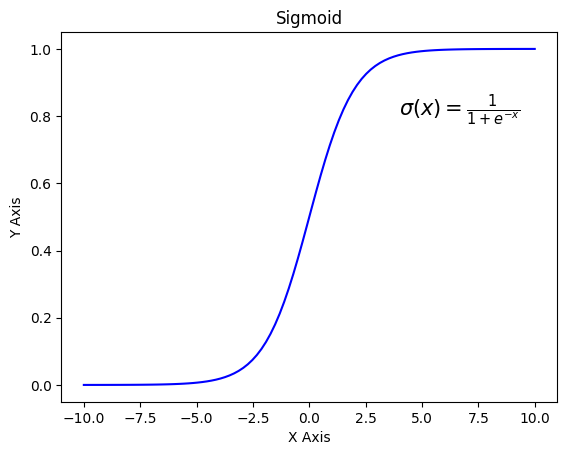

In [3]:
# generate an Array with value ???
# linespace generate an array from start and stop value
# with requested number of elements. Example 10 elements or 100 elements.
# 
x = plt.linspace(-10,10,100)

print(x.shape)
plt.title('Sigmoid')

plt.xlabel('X Axis')
plt.ylabel('Y Axis')
plt.text(4, 0.8, r'$\sigma(x)=\frac{1}{1+e^{-x}}$', fontsize=15)


# prepare the plot, associate the color r(ed) or b(lue) and the label 
#plt.plot(x, sigmoid(x), 'r', label='linspace(-10,10,10)')
plt.plot(x, sigmoid(x), 'b')

# Decision Boundary


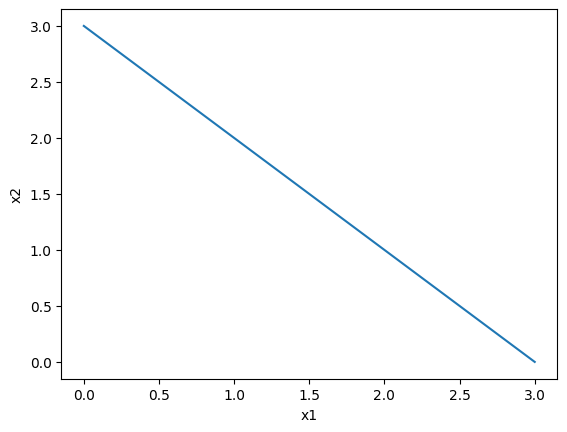

In [4]:
x1=[0,3]
x2=[3,0]
plt.xlabel('x1')
plt.ylabel('x2')
plt.plot(x1,x2)

# Kostenfunktion 

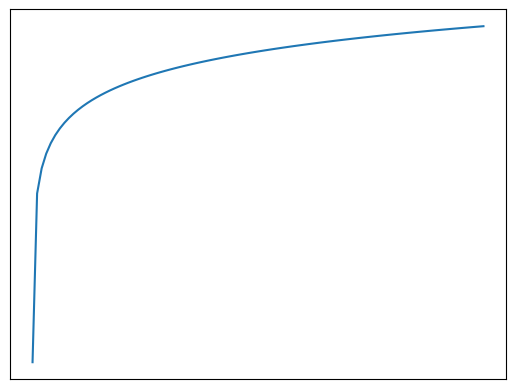

In [5]:

x = plt.linspace(0.0001,1,100)
y = np.log(x)
#print(x)
ax = plt.gca()
ax.get_xaxis().set_visible(False)
ax.get_yaxis().set_visible(False)
plt.plot(y)

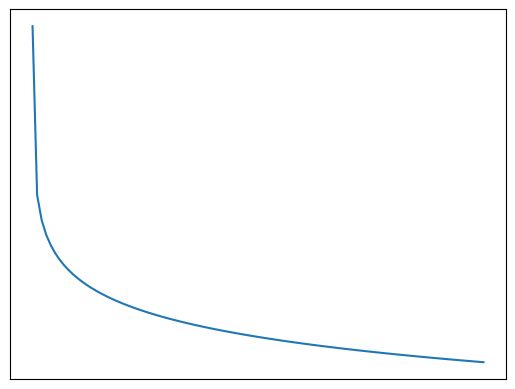

In [6]:
plt.plot(-y)
ax = plt.gca()
ax.get_xaxis().set_visible(False)
ax.get_yaxis().set_visible(False)


/var/folders/pb/9z396mvn5h50lm97gx3bv0j00000gn/T/ipykernel_84638/4099885985.py:2: RuntimeWarning: divide by zero encountered in log10
  y = np.log10(1-x)


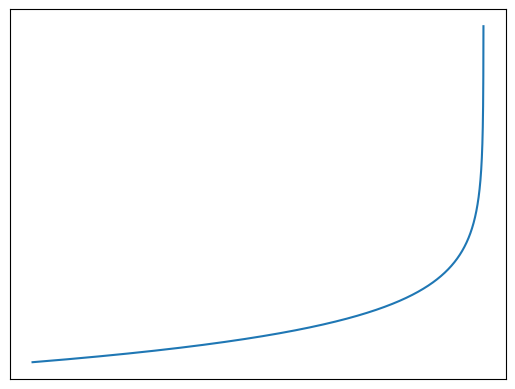

In [7]:
x = plt.linspace(0.0001,1,10000)
y = np.log10(1-x)
ax = plt.gca()
ax.get_xaxis().set_visible(False)
ax.get_yaxis().set_visible(False)
plt.plot(-y)

# 2-Klassen Problem mit SKLearn

In [8]:
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split


iris_dataset = load_iris()

#X=iris_dataset['data']
X=iris_dataset['data']
y=iris_dataset['target']

print(iris_dataset['DESCR'])



.. _iris_dataset:

Iris plants dataset
--------------------

**Data Set Characteristics:**

:Number of Instances: 150 (50 in each of three classes)
:Number of Attributes: 4 numeric, predictive attributes and the class
:Attribute Information:
    - sepal length in cm
    - sepal width in cm
    - petal length in cm
    - petal width in cm
    - class:
            - Iris-Setosa
            - Iris-Versicolour
            - Iris-Virginica

:Summary Statistics:

============== ==== ==== ======= ===== ====================
                Min  Max   Mean    SD   Class Correlation
============== ==== ==== ======= ===== ====================
sepal length:   4.3  7.9   5.84   0.83    0.7826
sepal width:    2.0  4.4   3.05   0.43   -0.4194
petal length:   1.0  6.9   3.76   1.76    0.9490  (high!)
petal width:    0.1  2.5   1.20   0.76    0.9565  (high!)
============== ==== ==== ======= ===== ====================

:Missing Attribute Values: None
:Class Distribution: 33.3% for each of 3 classes.
:Cr

In [9]:
y=y[:100]
X=X[:100]

print(X.shape)
print(y)

(Xtr,Xte,ytr,yte)=train_test_split(X,y)

print(Xtr.shape)

print(Xte.shape)


(100, 4)
[0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 0 0 0 0 0 0 0 0 0 0 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1
 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1]
(75, 4)
(25, 4)


In [10]:


class LogisticRegressionUsingGD:

    @staticmethod
    def sigmoid(x):
        # Activation function used to map any real value between 0 and 1
        return 1 / (1 + np.exp(-x))
    
    @staticmethod
    def net_input(weights, x):
        # Computes the weighted sum of inputs
        return np.dot(x, weights)
#....

In [11]:
#from sklearn.linear_model import LogisticRegression



#Xtr = np.c_[np.ones((Xtr.shape[0], 1)), X]
#ytr = ytr[:, np.newaxis]
weights = np.zeros((Xtr.shape[1], 1))



logreg = LogisticRegressionUsingGD()

logreg.fit(Xtr,ytr,weights)
o = logreg.predict(Xte)


import sklearn.metrics as eval
acc=eval.accuracy_score(yte,o)

print(acc)
print("Confusion Matrix")
print(eval.confusion_matrix(yte,o))



1.0
Confusion Matrix
[[15  0]
 [ 0 10]]


  NIT   NF   F                       GTG
    0    1  6.931471805599454E-01   8.68596444E-01
    1    5  1.560665287652577E-04   4.12564108E-07
tnc: fscale = 1556.88
    2    9  7.040070934931692E-07   5.76044538E-12
tnc: fscale = 416651
/var/folders/pb/9z396mvn5h50lm97gx3bv0j00000gn/T/ipykernel_84638/2997529239.py:26: RuntimeWarning: divide by zero encountered in log
  y * np.log(LogisticRegressionUsingGD.probability(weights, x)) + (1 - y) * np.log(
/var/folders/pb/9z396mvn5h50lm97gx3bv0j00000gn/T/ipykernel_84638/2997529239.py:26: RuntimeWarning: invalid value encountered in multiply
  y * np.log(LogisticRegressionUsingGD.probability(weights, x)) + (1 - y) * np.log(
    3   16  1.412468701636783E-07   2.27975590E-13
tnc: |pg| = 1.14597e-12 -> local minimum
    3   16  1.412468701636783E-07   2.27975590E-13
tnc: Local minima reach (|pg| ~= 0)


## Multiklassen Erweiterung

.. _digits_dataset:

Optical recognition of handwritten digits dataset
--------------------------------------------------

**Data Set Characteristics:**

:Number of Instances: 1797
:Number of Attributes: 64
:Attribute Information: 8x8 image of integer pixels in the range 0..16.
:Missing Attribute Values: None
:Creator: E. Alpaydin (alpaydin '@' boun.edu.tr)
:Date: July; 1998

This is a copy of the test set of the UCI ML hand-written digits datasets
https://archive.ics.uci.edu/ml/datasets/Optical+Recognition+of+Handwritten+Digits

The data set contains images of hand-written digits: 10 classes where
each class refers to a digit.

Preprocessing programs made available by NIST were used to extract
normalized bitmaps of handwritten digits from a preprinted form. From a
total of 43 people, 30 contributed to the training set and different 13
to the test set. 32x32 bitmaps are divided into nonoverlapping blocks of
4x4 and the number of on pixels are counted in each block. This generates
an in

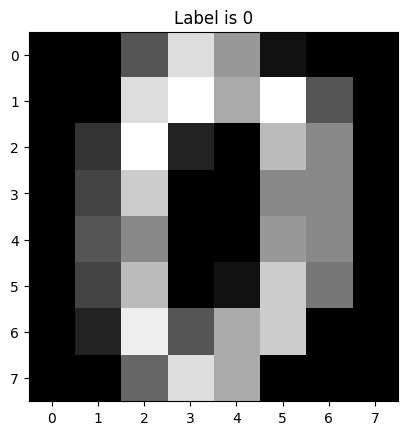

In [12]:


from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn import datasets
from skimage import exposure
import numpy as np
import matplotlib.pyplot as plt

# load the MNIST digits dataset
mnist = datasets.load_digits()


print(mnist["DESCR"])

# take the MNIST data and construct the training and testing split, using 75% of the
# data for training and 25% for testing

(Xtr, Xte, ytr, yte) = train_test_split(np.array(mnist.data),
mnist.target, test_size=0.25, random_state=42)
print(mnist.data[0].shape)
pixels = np.array(mnist.data[0], dtype='uint8')
pixels = pixels.reshape((8, 8))
plt.title('Label is {label}'.format(label=mnist.target[0]))
plt.imshow(pixels, cmap='gray')
plt.show()





In [13]:
from sklearn.linear_model import LogisticRegression


model = LogisticRegression(solver='liblinear')

model.fit(Xtr, ytr)
o = model.predict(Xte)



import sklearn.metrics as eval
acc=eval.accuracy_score(yte,o)

print(acc)
print("Confusion Matrix")
print(eval.confusion_matrix(yte,o))







0.9666666666666667
Confusion Matrix
[[42  0  0  0  1  0  0  0  0  0]
 [ 0 36  0  0  0  0  0  0  1  0]
 [ 0  0 38  0  0  0  0  0  0  0]
 [ 0  0  0 44  0  1  0  0  1  0]
 [ 0  1  0  0 54  0  0  0  0  0]
 [ 0  0  1  0  0 56  0  0  1  1]
 [ 0  0  0  0  0  1 44  0  0  0]
 [ 0  0  0  0  0  0  0 40  0  1]
 [ 0  1  0  0  0  1  0  0 36  0]
 [ 0  0  0  0  0  0  0  0  3 45]]


# Merkmalnormierung


In [14]:
from sklearn.preprocessing import MinMaxScaler
data = [[-1, 2], [-0.5, 6], [0, 10], [1, 18]]

scaler = MinMaxScaler()
scaler.fit(data)
#print(scaler.fit(data))

print("min,max:")
print(scaler.data_max_)
print(scaler.data_min_)

print("transformed:")

print(scaler.transform(data))



min,max:
[ 1. 18.]
[-1.  2.]
transformed:
[[0.   0.  ]
 [0.25 0.25]
 [0.5  0.5 ]
 [1.   1.  ]]


In [15]:
myscaler = MinMaxScaler()
myscaler.fit(Xtr)
Xtr_minmax=myscaler.transform(Xtr)
Xte_minmax=myscaler.transform(Xte)


model = LogisticRegression(solver='liblinear')

model.fit(Xtr_minmax, ytr)
o = model.predict(Xte_minmax)



import sklearn.metrics as eval
acc=eval.accuracy_score(yte,o)

print(acc)
print("Confusion Matrix")
print(eval.confusion_matrix(yte,o))


0.9622222222222222
Confusion Matrix
[[43  0  0  0  0  0  0  0  0  0]
 [ 0 35  2  0  0  0  0  0  0  0]
 [ 0  0 38  0  0  0  0  0  0  0]
 [ 0  0  0 42  0  1  0  0  3  0]
 [ 0  1  0  0 54  0  0  0  0  0]
 [ 0  0  0  0  0 56  1  0  0  2]
 [ 0  0  0  0  0  1 44  0  0  0]
 [ 0  0  0  0  0  0  0 40  0  1]
 [ 0  1  0  0  0  1  0  0 36  0]
 [ 0  0  0  0  0  1  0  0  2 45]]


In [16]:
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()
scaler.fit(Xtr)

Xtr_std = scaler.transform(Xtr)
Xte_std = scaler.transform(Xte)


model = LogisticRegression(solver='liblinear')

model.fit(Xtr_std, ytr)
o = model.predict(Xte_std)


import sklearn.metrics as eval
acc=eval.accuracy_score(yte,o)

print(acc)
print("Confusion Matrix")
print(eval.confusion_matrix(yte,o))



0.9666666666666667
Confusion Matrix
[[43  0  0  0  0  0  0  0  0  0]
 [ 0 36  1  0  0  0  0  0  0  0]
 [ 0  0 38  0  0  0  0  0  0  0]
 [ 0  0  0 43  0  1  0  0  2  0]
 [ 0  1  0  0 54  0  0  0  0  0]
 [ 0  0  0  0  0 57  1  0  0  1]
 [ 0  0  0  0  0  1 44  0  0  0]
 [ 0  0  0  0  0  0  0 40  0  1]
 [ 0  2  0  0  0  1  0  0 35  0]
 [ 0  0  0  0  0  1  0  0  2 45]]
